# 01 Revisión práctica de Machine Learning

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

In [300]:
from sklearn.datasets import load_iris
import pandas as pd

In [301]:
data_iris = load_iris()
print(data_iris.DESCR)
print(data_iris.feature_names)
X = data_iris.data
y = data_iris.target
print('Dimension de la matriz de caracteristicas =', X.shape)
print('Dimension del vector de etiquetas =', y.shape)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

## **Respuestas**
1. Cada instancia representa una de las 3 especies de la flor iris
2. Se tiene un total de 150 instancias y un total de 4 caracteristicas.
3. Caracteristicas
   - sepal length (cm): longitud del sepal (base de la flo entre el tallo y los petalos) de la flor en centímetros.
   - sepal width (cm): ancho del sepal de la flor en centímetros.
   - petal length (cm): longitud del petalo de la flor en centímetros.
   - petal width (cm) ancho del petalo en centímetros.
4. Existen 3 clases que corresponden a las 3 especies de flores iris ('Iris-Setosa' 'Iris-Versicolour' 'Iris-Virginica') y cada clase cuenta con 50 instancias.
5. La matriz de caracteristicas posee una dimension de 150 filas por 4 columnas. La dimension del vector de etiquetas es de 150.

## **Tabla**

In [302]:
df_iris = pd.DataFrame(data_iris.data, columns=data_iris.feature_names)
df_iris['clases'] = data_iris.target
df_iris.head(5)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),clases
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## **Gráfico de Distribucion de Clases**

<Axes: xlabel='clases'>

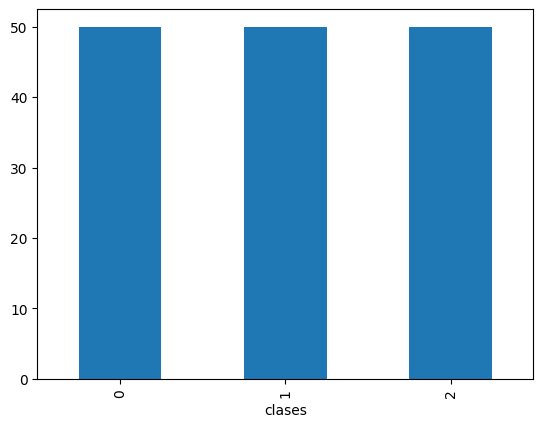

In [303]:
df_iris['clases'].value_counts().plot(kind='bar')

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
   - Regresión logística multiclase, SVM lineal y MLP de clasificación.
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
   - Regresión logística y Gaussian Naive Bayes.
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?
   - Porque el rendimiento depende de como esten distribuidos los datos y, aunque se puede determinar que modelos son mas adecuados para cada caso, no es posible saber cual siempre va a dar el mejor resultado.

## Configuraciones Iniciales

In [304]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

In [305]:
# Separacion de datos

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=1/3, random_state=42, stratify=y_temp
)

# Estandarizacion

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

## Gaussian Naive Bayes

In [306]:
from sklearn.naive_bayes import GaussianNB

In [307]:
gnb = GaussianNB()
gnb.fit(X_train_scaled, y_train)
y_pred_val_gnb = gnb.predict(X_val_scaled)

print(f"Gaussian Naive Bayes - Val Accuracy: {accuracy_score(y_val, y_pred_val_gnb):.4f} - Val F1 Macro: {f1_score(y_val, y_pred_val_gnb, average='macro'):.4f}")

Gaussian Naive Bayes - Val Accuracy: 0.8667 - Val F1 Macro: 0.8653


## Regresión logística multiclase

In [308]:
from sklearn.linear_model import LogisticRegression

In [309]:
log_reg = LogisticRegression(multi_class='multinomial', max_iter=200, random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_pred_val_lr = log_reg.predict(X_val_scaled)

print(f"Regresión Logística - Val Accuracy: {accuracy_score(y_val, y_pred_val_lr):.4f} - Val F1 Macro: {f1_score(y_val, y_pred_val_lr, average='macro'):.4f}")

Regresión Logística - Val Accuracy: 0.8667 - Val F1 Macro: 0.8653


c:\Users\franc\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


## SVM lineal

In [310]:
from sklearn.svm import SVC

In [311]:
svm_lin = SVC(kernel='linear', random_state=42)
svm_lin.fit(X_train_scaled, y_train)
y_pred_val_svm = svm_lin.predict(X_val_scaled)

print(f"SVM Lineal - Val Accuracy: {accuracy_score(y_val, y_pred_val_svm):.4f} - Val F1 Macro: {f1_score(y_val, y_pred_val_svm, average='macro'):.4f}")

SVM Lineal - Val Accuracy: 0.8667 - Val F1 Macro: 0.8653


## Árbol de decisión

In [312]:
from sklearn.tree import DecisionTreeClassifier

In [313]:
tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(X_train_scaled, y_train)
y_pred_val_tree = tree_clf.predict(X_val_scaled)

print(f"Árbol de Decisión - Val Accuracy: {accuracy_score(y_val, y_pred_val_tree):.4f} - Val F1 Macro: {f1_score(y_val, y_pred_val_tree, average='macro'):.4f}")

Árbol de Decisión - Val Accuracy: 0.8667 - Val F1 Macro: 0.8653


## Random Forest

In [314]:
from sklearn.ensemble import RandomForestClassifier

In [315]:
rf_clf = RandomForestClassifier(random_state=42)
rf_clf.fit(X_train_scaled, y_train)
y_pred_val_rf = rf_clf.predict(X_val_scaled)

print(f"Random Forest - Val Accuracy: {accuracy_score(y_val, y_pred_val_rf):.4f} - Val F1 Macro: {f1_score(y_val, y_pred_val_rf, average='macro'):.4f}")

Random Forest - Val Accuracy: 0.8667 - Val F1 Macro: 0.8653


## Gradient Boosting

In [316]:
from sklearn.ensemble import GradientBoostingClassifier

In [317]:
gb_clf = GradientBoostingClassifier(random_state=42)
gb_clf.fit(X_train_scaled, y_train)
y_pred_val_gb = gb_clf.predict(X_val_scaled)

print(f"Gradient Boosting - Val Accuracy: {accuracy_score(y_val, y_pred_val_gb):.4f} - Val F1 Macro: {f1_score(y_val, y_pred_val_gb, average='macro'):.4f}")

Gradient Boosting - Val Accuracy: 0.9333 - Val F1 Macro: 0.9327


## MLP de clasificación

In [318]:
from sklearn.neural_network import MLPClassifier

In [319]:
mlp_clf = MLPClassifier(hidden_layer_sizes=(10,), max_iter=500, random_state=42)
mlp_clf.fit(X_train_scaled, y_train)
y_pred_val_mlp = mlp_clf.predict(X_val_scaled)

print(f"MLP - Val Accuracy: {accuracy_score(y_val, y_pred_val_mlp):.4f} - Val F1 Macro: {f1_score(y_val, y_pred_val_mlp, average='macro'):.4f}")

MLP - Val Accuracy: 0.9000 - Val F1 Macro: 0.8997


c:\Users\franc\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


## Evaluación sobre la partición de prueba

In [320]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

modelos = {
    "Gaussian Naive Bayes": gnb,
    "Regresión Logística": log_reg,
    "SVM Lineal": svm_lin,
    "Árbol de Decisión": tree_clf,
    "Random Forest": rf_clf,
    "Gradient Boosting": gb_clf,
    "MLP de clasificación": mlp_clf
}

resultados = []

for nombre, modelo in modelos.items():
    y_pred_test = modelo.predict(X_test_scaled)
    
    resultados.append({
        "Modelo": nombre,
        "Transformación": "StandardScaler",
        "Hiperparámetros principales": "Por defecto",
        "Accuracy de prueba": round(accuracy_score(y_test, y_pred_test), 4),
        "F1 macro de prueba": round(f1_score(y_test, y_pred_test, average='macro'), 4)
    })

df_resultados = pd.DataFrame(resultados)

## Resultados

In [321]:
display(df_resultados)

,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,Gaussian Naive Bayes,StandardScaler,Por defecto,1.0000,1.0000
1,Regresión Logística,StandardScaler,Por defecto,1.0000,1.0000
2,SVM Lineal,StandardScaler,Por defecto,1.0000,1.0000
3,Árbol de Decisión,StandardScaler,Por defecto,1.0000,1.0000
4,Random Forest,StandardScaler,Por defecto,0.9333,0.9327
5,Gradient Boosting,StandardScaler,Por defecto,0.9333,0.9327
6,MLP de clasificación,StandardScaler,Por defecto,1.0000,1.0000


## Matrices de confusión

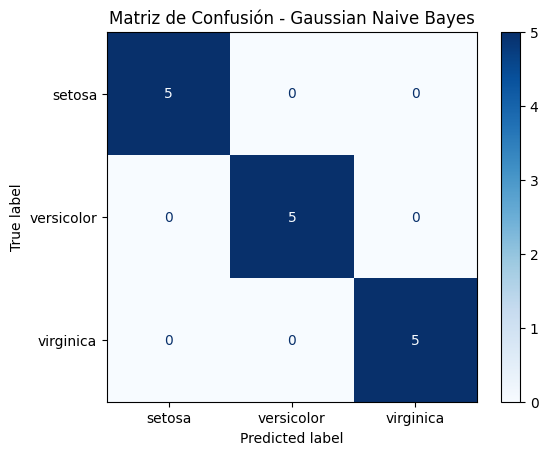

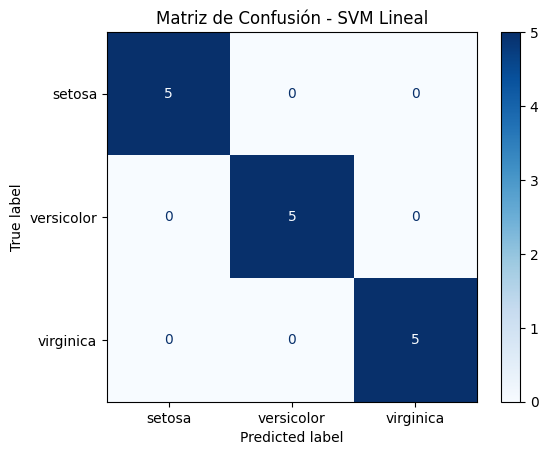

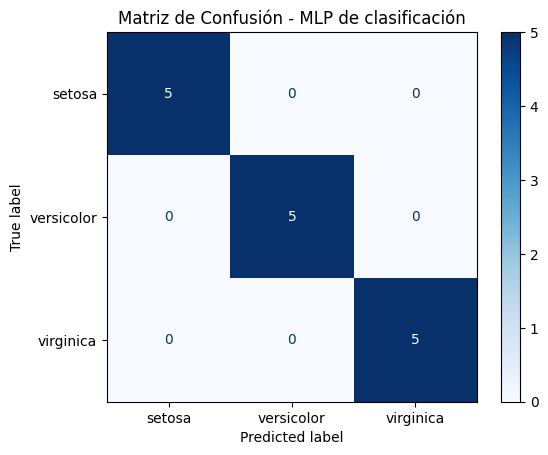

In [322]:
modelos_a_graficar = {
    "Gaussian Naive Bayes": gnb,
    "SVM Lineal": svm_lin,
    "MLP de clasificación": mlp_clf
}

for nombre, modelo in modelos_a_graficar.items():
    y_pred_test = modelo.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred_test)
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data_iris.target_names)
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"Matriz de Confusión - {nombre}")
    plt.show()

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
    - MLP mostró el mejor desempeño global, fue el segundo mejor en validación (accuracy 0.90, F1 macro 0.8997) y alcanzó 1.0 en test para accuracy y F1 macro. Sin embargo, GNB, regresión logística, SVM lineal y árbol también obtuvieron 1.0 en test.
2. ¿Cuál fue el modelo más sencillo de programar?
    - El modelo mas facil de programar fue Gaussian Naive Bayes al instancia sin argumentos y no requerir que esten estrictamente escalados los datos.
3. ¿Accuracy y F1 macro cuentan la misma historia?
    - Sí, en este caso cuentan la misma historia. Al existir un balanceo parejo entre las 3 clases, no hay una clase mayoritaria que distorsione la Accuracy. Por lo tanto, la accuracy de 0.9333 coincide casi exactamente con el F1 Macro de 0.9327.
4. ¿Cuál es la diferencia entre las métricas macro y micro?
    - Macro calcula la métrica por clase y promedia, así que todas las clases pesan igual. Permitiendo castigar fallas en clases minoritarias.
    - Micro suma aciertos y errores (TP, FP, FN) de todas las clases y calcula una sola métrica, por lo que si hay clases dominantes el error de las minoritarias no es representativo.
5. ¿Qué aporta el MLP frente a un modelo lineal?
    - Un modelo lineal separa las clases con hiperplanos. El MLP tiene una capa oculta con activación no lineal, así que puede aprender fronteras curvas e interacciones entre características.

##### **Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.**

In [323]:
import numpy as np

errores = {}
predicciones_modelos = {} 

for nombre, modelo in modelos.items():
    pred = modelo.predict(X_val_scaled)
    for i in np.where(pred != y_val)[0]:
        errores.setdefault(i, []).append(nombre)
        clase_predicha = data_iris.target_names[pred[i]]
        predicciones_modelos.setdefault(i, {})[nombre] = clase_predicha

print(f"{'Índice':<6} | {'Clase Real':<11} | {'Características':<22} | Detalle de Predicciones por Modelo")
print("-" * 100)

for i, fallan in sorted(errores.items(), key=lambda x: -len(x[1])):
    clase_real = data_iris.target_names[y_val[i]]
    caracteristicas = str(X_val[i])
    detalle_fallos = ", ".join([f"'{m}': -> {predicciones_modelos[i][m]}" for m in fallan])
    
    print(f"{i:<6} | {clase_real:<11} | {caracteristicas:<22} | {detalle_fallos}")


Índice | Clase Real  | Características        | Detalle de Predicciones por Modelo
----------------------------------------------------------------------------------------------------
11     | virginica   | [4.9 2.5 4.5 1.7]      | 'Gaussian Naive Bayes': -> versicolor, 'Regresión Logística': -> versicolor, 'SVM Lineal': -> versicolor, 'Árbol de Decisión': -> versicolor, 'Random Forest': -> versicolor, 'Gradient Boosting': -> versicolor
16     | versicolor  | [6.7 3.  5.  1.7]      | 'Gaussian Naive Bayes': -> virginica, 'Regresión Logística': -> virginica, 'SVM Lineal': -> virginica, 'Árbol de Decisión': -> virginica, 'Random Forest': -> virginica, 'MLP de clasificación': -> virginica
28     | virginica   | [6.3 2.8 5.1 1.5]      | 'Gaussian Naive Bayes': -> versicolor, 'Regresión Logística': -> versicolor, 'SVM Lineal': -> versicolor, 'Random Forest': -> versicolor, 'Gradient Boosting': -> versicolor, 'MLP de clasificación': -> versicolor
0      | virginica   | [6.1 2.6 5.6 1.4]     

In [324]:
df = pd.DataFrame(data_iris.data, columns=data_iris.feature_names)
df['especie'] = [data_iris.target_names[i] for i in data_iris.target]
resumen_completo = df.groupby('especie').agg(['mean', 'std'])

print("PROPORCIONES PROMEDIO POR ESPECIE (Dataset Completo)")
print(resumen_completo.round(2).to_string())



PROPORCIONES PROMEDIO POR ESPECIE (Dataset Completo)
           sepal length (cm)       sepal width (cm)       petal length (cm)       petal width (cm)      
                        mean   std             mean   std              mean   std             mean   std
especie                                                                                                 
setosa                  5.01  0.35             3.43  0.38              1.46  0.17             0.25  0.11
versicolor              5.94  0.52             2.77  0.31              4.26  0.47             1.33  0.20
virginica               6.59  0.64             2.97  0.32              5.55  0.55             2.03  0.27


Los errores de clasificación seleccionados son la muestra 11 y 16 del conjunto de validación.

**Análisis de características**
1. La muestra 11 es una virginica atípica. Su largo de sépalo (4.9) está a -2.6 desviaciones del promedio de virginica, y su largo de pétalo (4.5) queda casi en el promedio de versicolor (4.26). Solo el ancho de pétalo (1.7) queda más cerca de virginica que de versicolor.
2. La muestra 16 es una versicolor atípica. Sus cuatro medidas quedan más cerca del promedio de virginica que del de versicolor. El largo y ancho de sépalo coinciden casi exactamente con los de virginica.

**Qué se puede concluir**
- Ambos errores ocurren entre versicolor y virginica.
- En ambas sus medidas del sepalo y petalo se parecen más a la clase equivocada que a la propia.
- Diferentes modelos comenten el mismo error con la misma clase.

**Qué no se puede concluir**
- Cual característica causó el error.
- Si hubo un error de medicion.
- Cuál modelo es mejor.

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

In [325]:
from sklearn.datasets import load_diabetes

data_diabetes = load_diabetes()
print(data_diabetes.DESCR)
print(data_diabetes.feature_names)
X_diab = data_diabetes.data
y_diab = data_diabetes.target
print('Dimension de la matriz de caracteristicas =', X_diab.shape)
print('Dimension del vector objetivo =', y_diab.shape)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

**Objetivo númerico**

El objetivo es una medida cuantitativa de la progresión de la enfermedad un año después de la medición inicial.

**Variables del dataset**

El dataset contiene 442 pacientes con diabetes y 10 variables:
- age: edad en años.
- sex: sexo del paciente.
- bmi: índice de masa corporal.
- bp: presión arterial promedio.
- s1 (tc): colesterol total en suero.
- s2 (ldl): lipoproteínas de baja densidad.
- s3 (hdl): lipoproteínas de alta densidad.
- s4 (tch): colesterol total / HDL.
- s5 (ltg): posiblemente el logaritmo del nivel de triglicéridos en suero.
- s6 (glu): nivel de glucosa en sangre.

**Transformaciones en las características**

La descripción indica que las 10 características ya incluyen transformaciones: fueron centradas en la media y escaladas por la desviación estándar multiplicada por la raíz de n_muestras.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

No, un modelo más flexible no siempre produce un menor error en datos nuevos. Una mayor flexibilidad permite ajustar mejor los datos de entrenamiento y reducir su error, pero también aumenta el riesgo de sobreajuste: el modelo se vuelve sensible a las fluctuaciones y al ruido de esos datos y los aprende como si fueran un patrón real.

## Modelos

## Configuraciones Iniciales

In [326]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [327]:
# Separacion de datos 
Xd_train, Xd_temp, yd_train, yd_temp = train_test_split(
    X_diab, y_diab, test_size=0.3, random_state=42
)
Xd_val, Xd_test, yd_val, yd_test = train_test_split(
    Xd_temp, yd_temp, test_size=1/3, random_state=42
)

# Metricas de validacion
def reporte(nombre, y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred)
    print(f"{nombre} - Val MAE: {mae:.2f} - Val RMSE: {rmse:.2f} - Val R²: {r2:.4f}")

## Regresión lineal

In [328]:
from sklearn.linear_model import LinearRegression

reg_lin = make_pipeline(StandardScaler(), LinearRegression())
reg_lin.fit(Xd_train, yd_train)
y_pred_val_lin = reg_lin.predict(Xd_val)
reporte("Regresión lineal", yd_val, y_pred_val_lin)

Regresión lineal - Val MAE: 37.64 - Val RMSE: 49.25 - Val R²: 0.5287


## Ridge

In [329]:
from sklearn.linear_model import Ridge

rmse = lambda y, p: np.sqrt(mean_squared_error(y, p))

filas = []
for a in [0.001, 0.01, 0.1, 1, 10, 100, 1000]:
    m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(Xd_train, yd_train)
    c = m[-1].coef_
    filas.append([a, rmse(yd_train, m.predict(Xd_train)), rmse(yd_val, m.predict(Xd_val)),
              r2_score(yd_val, m.predict(Xd_val)),
              np.abs(c).sum(), (c == 0).sum()])

df_ridge = pd.DataFrame(filas, columns=["alpha", "RMSE train", "RMSE val", "R² val", "Suma |coef|", "Coef = 0"])
display(df_ridge.round(2))

# Seleccion por menor RMSE de validacion y reajuste
alpha_ridge = df_ridge.sort_values("RMSE val").iloc[0]["alpha"]
print("alpha elegido para Ridge:", alpha_ridge)
ridge = make_pipeline(StandardScaler(), Ridge(alpha=alpha_ridge)).fit(Xd_train, yd_train)

,alpha,RMSE train,RMSE val,R² val,Suma |coef|,Coef = 0
0,0.00,54.07,49.25,0.53,179.37,0
1,0.01,54.07,49.25,0.53,179.04,0
2,0.10,54.07,49.23,0.53,175.81,0
3,1.00,54.09,49.10,0.53,151.62,0
4,10.00,54.25,48.80,0.54,109.37,0
5,100.00,55.12,48.68,0.54,88.36,0
6,1000.00,63.89,56.35,0.38,38.96,0


alpha elegido para Ridge: 100.0


## Lasso

In [330]:
from sklearn.linear_model import Lasso

filas = []
for a in [0.001, 0.01, 0.1, 1, 10, 100, 1000]:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a)).fit(Xd_train, yd_train)
    c = m[-1].coef_
    filas.append([a, rmse(yd_train, m.predict(Xd_train)), rmse(yd_val, m.predict(Xd_val)),
                  r2_score(yd_val, m.predict(Xd_val)),
                  np.abs(c).sum(), (c == 0).sum()])

df_lasso = pd.DataFrame(filas, columns=["alpha", "RMSE train", "RMSE val", "R² val", "Suma |coef|", "Coef = 0"])
display(df_lasso.round({"RMSE train": 2, "RMSE val": 2, "R² val": 4, "Suma |coef|": 2}))

# Seleccion por menor RMSE de validacion y reajuste
alpha_lasso = df_lasso.sort_values("RMSE val").iloc[0]["alpha"]
print("alpha elegido para Lasso:", alpha_lasso)
lasso = make_pipeline(StandardScaler(), Lasso(alpha=alpha_lasso)).fit(Xd_train, yd_train)

,alpha,RMSE train,RMSE val,R² val,Suma |coef|,Coef = 0
0,0.001,54.07,49.25,0.5288,179.00,0
1,0.010,54.07,49.22,0.5292,175.29,0
2,0.100,54.10,49.05,0.5326,144.14,1
3,1.000,54.37,48.53,0.5424,98.39,1
4,10.000,57.58,50.71,0.5003,54.50,6
5,100.000,78.41,72.22,-0.0135,0.00,10
6,1000.000,78.41,72.22,-0.0135,0.00,10


alpha elegido para Lasso: 1.0



## kNN de regresión

In [331]:
from sklearn.neighbors import KNeighborsRegressor

knn = make_pipeline(StandardScaler(), KNeighborsRegressor())
knn.fit(Xd_train, yd_train)
y_pred_val_knn = knn.predict(Xd_val)
reporte("kNN", yd_val, y_pred_val_knn)

kNN - Val MAE: 41.15 - Val RMSE: 53.68 - Val R²: 0.4401


## Árbol de regresión

In [332]:
from sklearn.tree import DecisionTreeRegressor

tree_reg = DecisionTreeRegressor(random_state=42)
tree_reg.fit(Xd_train, yd_train)
y_pred_val_tree = tree_reg.predict(Xd_val)
reporte("Árbol de regresión", yd_val, y_pred_val_tree)

Árbol de regresión - Val MAE: 60.23 - Val RMSE: 77.74 - Val R²: -0.1744


## Random Forest de regresión

In [333]:
from sklearn.ensemble import RandomForestRegressor

rf_reg = RandomForestRegressor(random_state=42)
rf_reg.fit(Xd_train, yd_train)
y_pred_val_rf = rf_reg.predict(Xd_val)
reporte("Random Forest", yd_val, y_pred_val_rf)

Random Forest - Val MAE: 40.36 - Val RMSE: 52.17 - Val R²: 0.4711



## Gradient Boosting de regresión

In [334]:
from sklearn.ensemble import GradientBoostingRegressor

gb_reg = GradientBoostingRegressor(random_state=42)
gb_reg.fit(Xd_train, yd_train)
y_pred_val_gb = gb_reg.predict(Xd_val)
reporte("Gradient Boosting", yd_val, y_pred_val_gb)

Gradient Boosting - Val MAE: 42.89 - Val RMSE: 53.20 - Val R²: 0.4501


## MLP de regresión

In [335]:
from sklearn.neural_network import MLPRegressor

mlp_reg = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(24,), max_iter=2000, early_stopping=True, random_state=42)
    ),
    transformer=StandardScaler()
)
mlp_reg.fit(Xd_train, yd_train)
y_pred_val_mlp = mlp_reg.predict(Xd_val)
reporte("MLP de regresión", yd_val, y_pred_val_mlp)

MLP de regresión - Val MAE: 38.73 - Val RMSE: 49.42 - Val R²: 0.5254


## Evaluación de los modelos sobre los datos de prueba

In [336]:
modelos_reg = {
    "Regresión lineal": reg_lin,
    "Ridge": ridge,
    "Lasso": lasso,
    "kNN": knn,
    "Árbol de regresión": tree_reg,
    "Random Forest": rf_reg,
    "Gradient Boosting": gb_reg,
    "MLP de regresión": mlp_reg
}

resultados = []
for nombre, modelo in modelos_reg.items():
    y_pred_test = modelo.predict(Xd_test)
    resultados.append({
        "Modelo": nombre,
        "MAE": round(mean_absolute_error(yd_test, y_pred_test), 2),
        "RMSE": round(np.sqrt(mean_squared_error(yd_test, y_pred_test)), 2),
        "R²": round(r2_score(yd_test, y_pred_test), 4)
    })
df_resultados_reg = pd.DataFrame(resultados)
display(df_resultados_reg)

,Modelo,MAE,RMSE,R²
0,Regresión lineal,50.28,59.97,0.3857
1,Ridge,51.11,60.82,0.3684
2,Lasso,50.49,60.20,0.3812
3,kNN,51.94,63.66,0.3079
4,Árbol de regresión,59.60,70.86,0.1425
5,Random Forest,47.43,55.94,0.4657
6,Gradient Boosting,48.33,59.53,0.3948
7,MLP de regresión,50.86,63.52,0.3109


## Gráfico de valores reales frente a predicciones

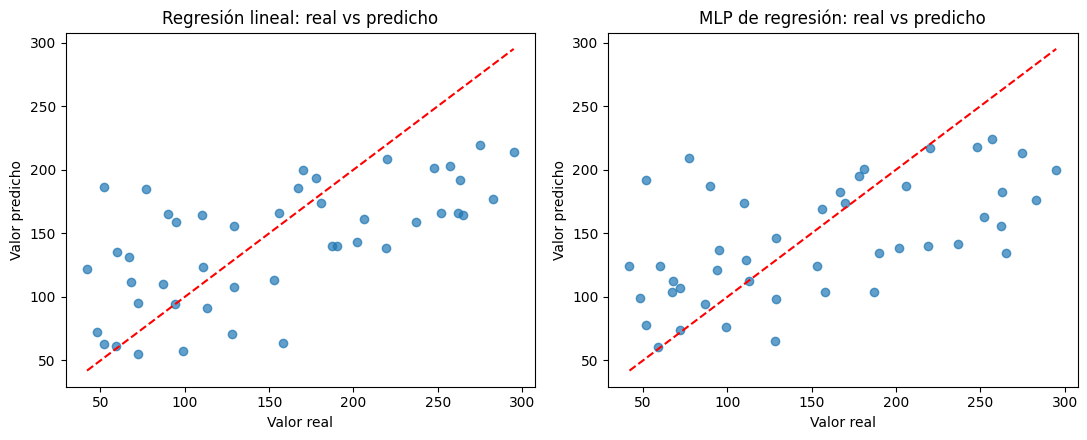

In [337]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
for eje, nombre in zip(ejes, ["Regresión lineal", "MLP de regresión"]):
    pred = modelos_reg[nombre].predict(Xd_test)
    eje.scatter(yd_test, pred, alpha=0.7)
    lim = [yd_test.min(), yd_test.max()]
    eje.plot(lim, lim, "r--")
    eje.set_title(f"{nombre}: real vs predicho")
    eje.set_xlabel("Valor real")
    eje.set_ylabel("Valor predicho")

plt.tight_layout()
plt.show()

## Gráfico de residuos

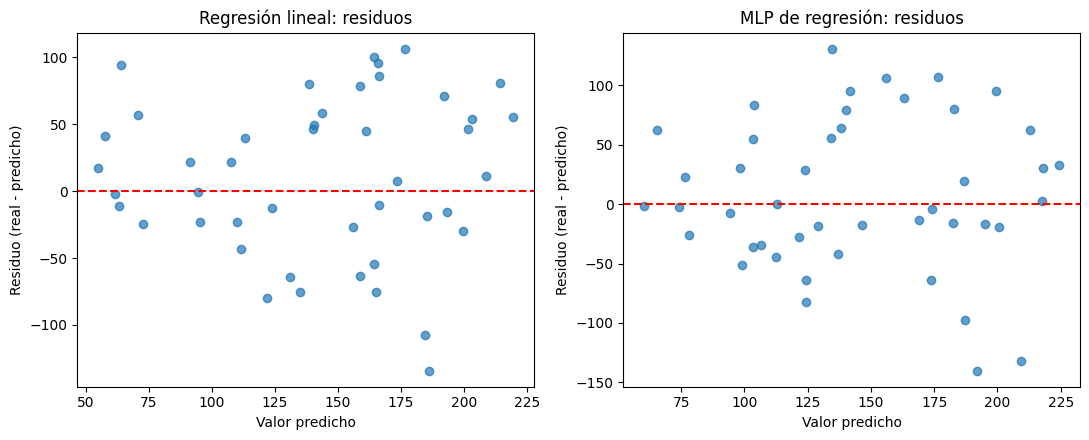

In [338]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
for eje, nombre in zip(ejes, ["Regresión lineal", "MLP de regresión"]):
    pred = modelos_reg[nombre].predict(Xd_test)
    residuo = yd_test - pred
    eje.scatter(pred, residuo, alpha=0.7)
    eje.axhline(0, color="r", linestyle="--")
    eje.set_title(f"{nombre}: residuos")
    eje.set_xlabel("Valor predicho")
    eje.set_ylabel("Residuo (real - predicho)")

plt.tight_layout()
plt.show()

## Dos ejemplos con errores absolutos grandes

In [339]:
filas = []
for nombre in ["Regresión lineal", "MLP de regresión"]:
    pred = modelos_reg[nombre].predict(Xd_test)
    err = np.abs(yd_test - pred)
    for i in np.argsort(err)[::-1][:2]:
        filas.append([nombre, i, yd_test[i], round(pred[i], 1), round(err[i], 1)])

df_errores = pd.DataFrame(filas, columns=["Modelo", "Posición (prueba)", "Real", "Predicho", "|Error|"])
display(df_errores)

,Modelo,Posición (prueba),Real,Predicho,|Error|
0,Regresión lineal,28,52.0,186.1,134.1
1,Regresión lineal,17,77.0,184.7,107.7
2,MLP de regresión,28,52.0,192.1,140.1
3,MLP de regresión,17,77.0,209.3,132.3




## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
    - En prueba, Random Forest tuvo el mejor desempeño en las tres métricas con MAE: 47.43, RMSE: 55.94, R²: 0.4657. En validación, en cambio, no fue de los mejores obteniendo MAE: 40.36, RMSE: 52.17, R²: 0.4711 y quedó por debajo de Lasso, Ridge, la regresión lineal y el MLP.
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
    - MAE promedia los errores en valor absoluto, de modo que todos pesan proporcionalmente, mientras que el RMSE los eleva al cuadrado y por eso penaliza mucho más los errores grandes.
3. ¿Cómo se interpreta un R² negativo?
    - Un R² negativo indica que el modelo predice peor que un modelo ingenuo que siempre devuelve el promedio.
4. ¿Qué efecto tuvo aumentar la regularización?
    - En Ridge, la suma de los coeficientes en valor absoluto bajó de 179 a 39, y en Lasso se fueron anulando coeficientes hasta llegar a los 10 con alpha = 100. El error de entrenamiento subió al aumentar alpha (RMSE de 54.07 a 63.89 en Ridge), porque el modelo se ajusta menos a los datos que ya vio. El error de validación mejoró de 49.25 a 48.68 en Ridge con alpha = 100, y a 48.53 en Lasso con alpha = 1. Al aumentar excesivamente Lasso con alpha = 100 predice siempre el promedio (RMSE 72.22).
5. ¿Qué puede explicar los errores grandes?
    - Los errores más grandes corresponden a los mismos dos pacientes en la regresión lineal y en el MLP. Lo que sugiere que la causa puede estar en los datos y no en el modelo.
6. ¿Un coeficiente predictivo demuestra una relación causal?
    - No, Un coeficiente alto o bajo solo indica que existe una asociación estadística o un patrón matemático útil para predecir el resultado, pero no prueba que esa característica sea la causa directa del fenómeno.